In [ ]:
# @title
!pip install rasterio

In [ ]:
import numpy as np
import pandas as pd
import rasterio
import os
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from google.colab import drive
from sklearn.preprocessing import StandardScaler

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading rasters...
(1260, 1900)
(1260, 1900)
(1260, 1900)
(1260, 1900)
(1260, 1900)
(1260, 1900)
(1260, 1900)
(1260, 1900)
Stack shape: (1260, 1900, 8)
Cleaned shape: (2379561, 8)

🔗 Pearson Correlation Matrix:
             river_dist  road_dist    aspect  fault_dist  thrust_dist  \
river_dist     1.000000   0.040435  0.004592   -0.032615    -0.060242   
road_dist      0.040435   1.000000 -0.008661    0.177767     0.439691   
aspect         0.004592  -0.008661  1.000000    0.005262     0.009617   
fault_dist    -0.032615   0.177767  0.005262    1.000000     0.338940   
thrust_dist   -0.060242   0.439691  0.009617    0.338940     1.000000   
slope         -0.009203  -0.026309  0.907336   -0.000114     0.006067   
ndvi           0.022689  -0.112199  0.014127    0.050123    -0.173343   
ndwi           0.022689  -0.112199  0.014127    0.050123    -0.173343   

                slope      ndvi      ndwi  
river_dist  -0.009203  0.022689  0.022689  
road_dist   -0.026309 -0.112199 -0.112199  

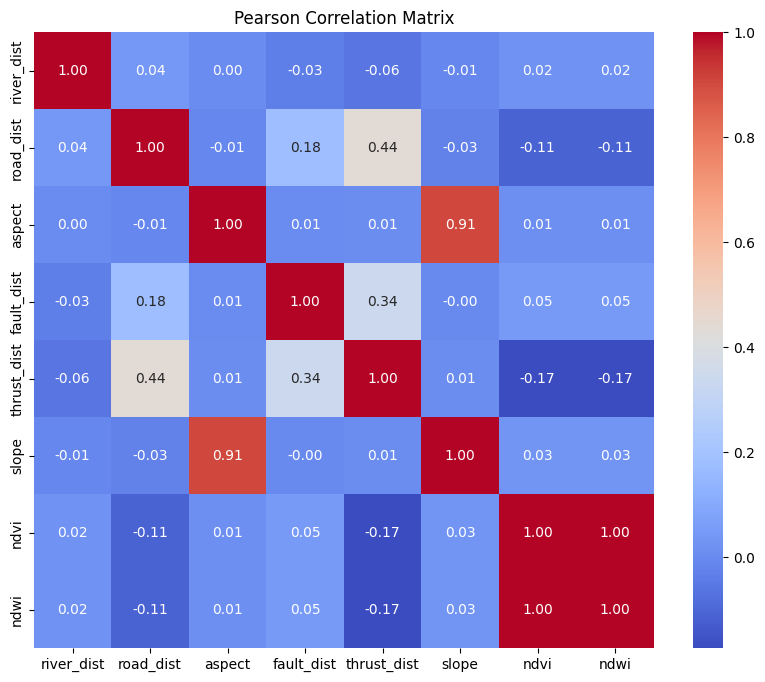


📊 Variance Inflation Factor (VIF) and Tolerance (TOL):


/usr/local/lib/python3.11/dist-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


      Variable       VIF  Tolerance
6         ndvi       inf   0.000000
7         ndwi       inf   0.000000
5        slope  5.687701   0.175818
2       aspect  5.678280   0.176110
4  thrust_dist  1.406152   0.711161
1    road_dist  1.253191   0.797963
3   fault_dist  1.147971   0.871102
0   river_dist  1.010771   0.989344


In [ ]:
# --- CONFIG ---
raster_files = [
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/river_dist.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/road_dist.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/resampled_aspect.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/resampled_fault_dist.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/resampled_thrust_dist.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/resampled_Slope.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/resampled_ndvi.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/resampled_ndvi.tif"

]

feature_names = [
    "river_dist", "road_dist", "aspect", "fault_dist",
    "thrust_dist", "slope", "ndvi","ndwi"
]
# --- END CONFIG ---

def load_rasters(raster_paths):
    arrays = []
    for path in raster_paths:
        with rasterio.open(path) as src:
            band = src.read(1).astype(np.float32)
            band[band == src.nodata] = np.nan
            arrays.append(band)
            print(src.shape)
    return np.stack(arrays, axis=-1)

def clean_data(data_stack):
    flat = data_stack.reshape(-1, data_stack.shape[-1])
    mask = ~np.isnan(flat).any(axis=1)
    return flat[mask]

def compute_vif_tolerance(df):
    vif_data = []
    for i in range(df.shape[1]):
        vif = variance_inflation_factor(df.values, i)
        tol = 1.0 / vif
        vif_data.append((df.columns[i], vif, tol))
    return pd.DataFrame(vif_data, columns=["Variable", "VIF", "Tolerance"])

# Load raster data
print("Loading rasters...")
stack = load_rasters(raster_files)
print("Stack shape:", stack.shape)

# Clean data (remove pixels with any NaNs)
cleaned = clean_data(stack)
print("Cleaned shape:", cleaned.shape)

# Optional: Standardize (for VIF stability)
scaler = StandardScaler()
scaled = scaler.fit_transform(cleaned)
df = pd.DataFrame(scaled, columns=feature_names)

# --- Pearson Correlation ---
print("\n🔗 Pearson Correlation Matrix:")
corr_matrix = df.corr()
print(corr_matrix)

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Pearson Correlation Matrix")
plt.show()

# --- VIF and TOL ---
print("\n📊 Variance Inflation Factor (VIF) and Tolerance (TOL):")
vif_df = compute_vif_tolerance(df)
print(vif_df.sort_values(by="VIF", ascending=False))
